In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle
%matplotlib inline
pd.set_option('display.max_columns', None)

C:\Users\tonya\AppData\Local\Temp\ipykernel_16468\1334464249.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
def parse_tick_file(path):
    """Parse a 'DateTime;Last;Bid;Ask;Vol' tick file.
    DateTime is 'YYYYMMDD HHMMSS fffffff' where fffffff is fractional
    seconds in 100ns ticks (.NET-style)."""
    df = pd.read_csv(path, sep=';', header=None, names=['dt_raw', 'Last', 'Bid', 'Ask', 'Vol'])
    parts = df['dt_raw'].str.split(' ', expand=True)
    base = pd.to_datetime(parts[0] + parts[1], format='%Y%m%d%H%M%S')
    frac = parts[2].astype(float) / 1e7
    df['DateTime'] = base + pd.to_timedelta(frac, unit='s')
    df = df.set_index('DateTime').sort_index()
    return df[['Last', 'Bid', 'Ask', 'Vol']]

def to_ohlcv(df, rule):
    ohlcv = df['Last'].resample(rule).ohlc()
    ohlcv['volume'] = df['Vol'].resample(rule).sum()
    return ohlcv.dropna(subset=['open'])

In [3]:
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Rectangle

def plot_candles(ohlcv, title, up='#0ca30c', down='#d03b3b'):
    """Vectorized OHLCV candlestick + volume chart.
    Up candles are drawn hollow, down candles filled solid -- a shape cue
    that keeps the up/down read usable for red-green color blindness."""
    x = mdates.date2num(ohlcv.index.to_pydatetime())
    o, h, l, c, v = (ohlcv[col].values for col in ['open', 'high', 'low', 'close', 'volume'])
    is_up = c >= o
    colors = np.where(is_up, up, down)
    width = (np.median(np.diff(x)) * 0.62) if len(x) > 1 else 1 / 1440

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True,
                                    gridspec_kw={'height_ratios': [3, 1]})

    segs = [[(xi, li), (xi, hi)] for xi, li, hi in zip(x, l, h)]
    ax1.add_collection(LineCollection(segs, colors=colors, linewidths=1))

    price_span = h.max() - l.min()
    min_body = max(price_span * 0.0008, 1e-6)
    patches = [Rectangle((xi - width / 2, min(oi, ci)), width, max(abs(ci - oi), min_body))
               for xi, oi, ci in zip(x, o, c)]
    face = ['none' if u else col for u, col in zip(is_up, colors)]
    pc = PatchCollection(patches, facecolor=face, edgecolor=list(colors), linewidths=1.2)
    ax1.add_collection(pc)

    ax1.set_xlim(x.min() - width, x.max() + width)
    ax1.set_ylim(l.min() - price_span * 0.05, h.max() + price_span * 0.05)
    ax2.bar(x, v, width=width, color=colors, alpha=0.6)

    ax1.set_title(title)
    ax1.set_ylabel('Price')
    ax1.grid(True, alpha=0.3)
    ax2.set_ylabel('Volume')
    ax2.grid(True, alpha=0.3)
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
    ax1.xaxis.set_major_locator(mdates.AutoDateLocator())
    plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

In [4]:
tick_path = r"C:\Users\tonya\Desktop\SpringBoardAssignments\Capstone_4\NQ 09-26_Tick_Last.txt"
ticks = parse_tick_file(tick_path)
print('ticks:', len(ticks))
print('range:', ticks.index.min(), '->', ticks.index.max())
ticks.head()

ticks: 869183
range: 2026-08-31 04:00:00.292000 -> 2026-09-01 20:42:10.256000


,Last,Bid,Ask,Vol
DateTime,,,,
2026-08-31 04:00:00.292,29352.50,29351.50,29352.50,1
2026-08-31 04:00:00.404,29352.75,29351.75,29352.75,1
2026-08-31 04:00:00.540,29351.75,29351.75,29352.50,1
2026-08-31 04:00:00.888,29352.25,29351.25,29352.25,1
2026-08-31 04:00:01.272,29351.50,29351.25,29351.50,1


In [5]:
ohlcv_1m = to_ohlcv(ticks, '1min')
ohlcv_5m = to_ohlcv(ticks, '5min')
print('1min bars:', len(ohlcv_1m))
print('5min bars:', len(ohlcv_5m))
ohlcv_1m.tail()

1min bars: 2383
5min bars: 477


,open,high,low,close,volume
DateTime,,,,,
2026-09-01 20:38:00,29138.50,29139.5,29137.00,29138.00,32
2026-09-01 20:39:00,29137.75,29138.0,29136.00,29137.50,35
2026-09-01 20:40:00,29137.25,29138.0,29134.50,29135.75,58
2026-09-01 20:41:00,29135.75,29136.5,29130.25,29133.75,94
2026-09-01 20:42:00,29134.00,29137.0,29134.00,29136.75,21


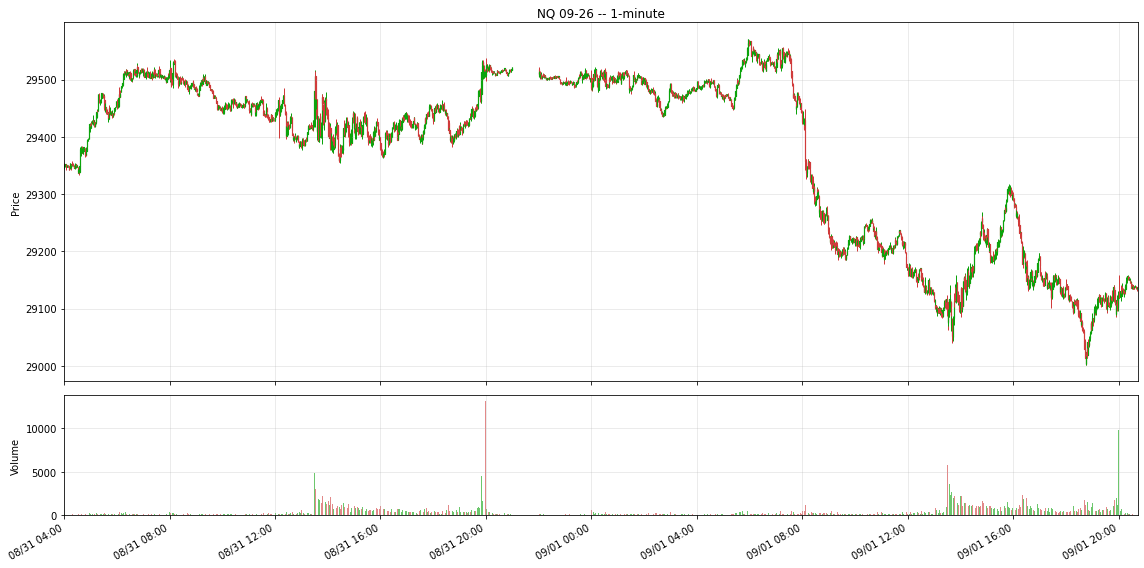

In [6]:
plot_candles(ohlcv_1m, 'NQ 09-26 -- 1-minute')

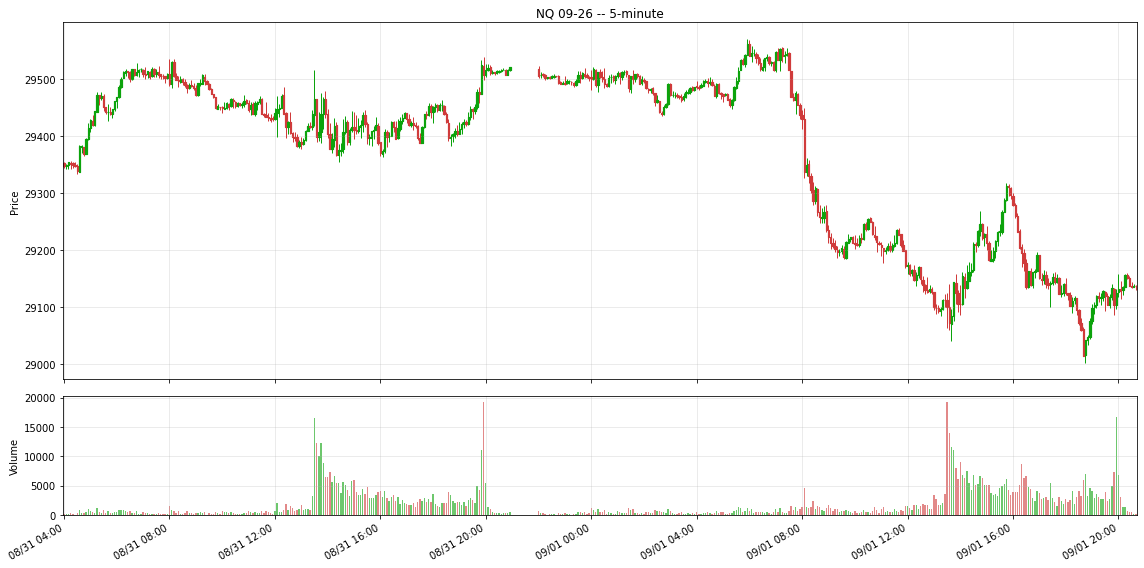

In [7]:
plot_candles(ohlcv_5m, 'NQ 09-26 -- 5-minute')

In [8]:
def to_ohlcv_by_ticks(df, n):
    """Tick bars: each bar = n consecutive trades, instead of a fixed time window."""
    grp = np.arange(len(df)) // n
    o = df['Last'].groupby(grp).first()
    h = df['Last'].groupby(grp).max()
    l = df['Last'].groupby(grp).min()
    c = df['Last'].groupby(grp).last()
    v = df['Vol'].groupby(grp).sum()
    t = df.index.to_series().groupby(grp).last()  # bar timestamped at its Nth (closing) trade
    return pd.DataFrame({'open': o.values, 'high': h.values, 'low': l.values,
                          'close': c.values, 'volume': v.values}, index=pd.DatetimeIndex(t.values, name='DateTime'))

TICKS_PER_BAR = 100
ohlcv_tick = to_ohlcv_by_ticks(ticks, TICKS_PER_BAR)
print(f'tick bars ({TICKS_PER_BAR} trades/bar):', len(ohlcv_tick))
ohlcv_tick.tail()

tick bars (100 trades/bar): 8692


,open,high,low,close,volume
DateTime,,,,,
2026-09-01 20:34:26.800,29136.75,29138.25,29133.50,29136.00,103
2026-09-01 20:36:37.428,29136.00,29139.25,29134.50,29137.75,119
2026-09-01 20:38:47.460,29137.50,29140.50,29137.00,29137.00,111
2026-09-01 20:41:23.756,29137.25,29138.00,29134.50,29135.50,120
2026-09-01 20:42:10.256,29135.50,29137.00,29130.25,29136.75,93


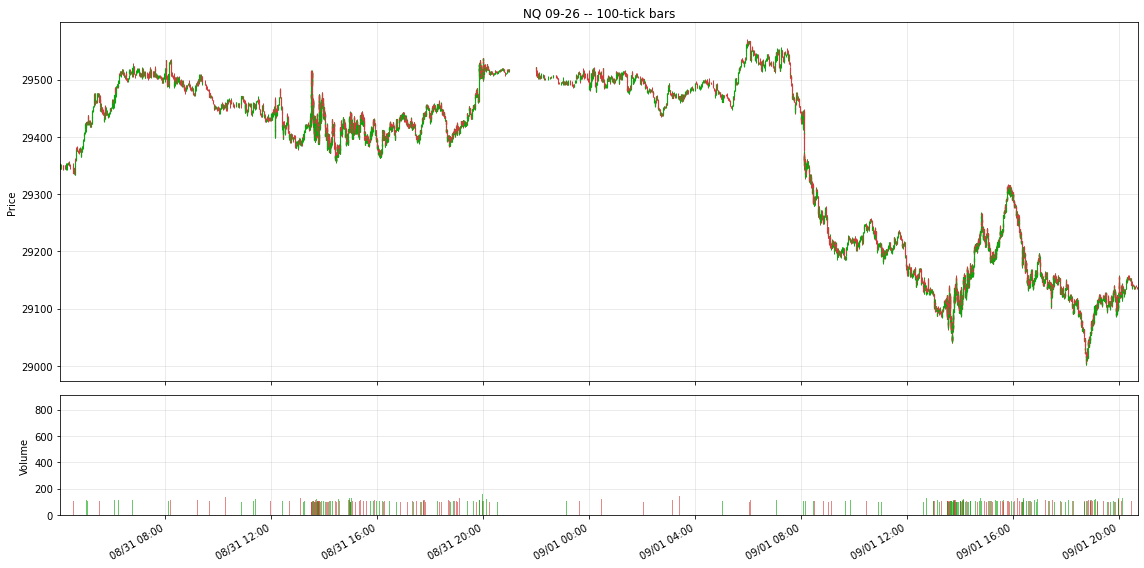

In [9]:
plot_candles(ohlcv_tick, f'NQ 09-26 -- {TICKS_PER_BAR}-tick bars')

In [10]:
def to_ohlcv_by_volume(df, vol_per_bar):
    """Volume bars: each bar closes once cumulative traded volume reaches
    vol_per_bar, instead of a fixed time window or fixed trade count.
    Drops the final bucket -- it's partial (data ran out before it filled)."""
    grp = (df['Vol'].cumsum() // vol_per_bar).astype(int)
    o = df['Last'].groupby(grp).first()
    h = df['Last'].groupby(grp).max()
    l = df['Last'].groupby(grp).min()
    c = df['Last'].groupby(grp).last()
    v = df['Vol'].groupby(grp).sum()
    t = df.index.to_series().groupby(grp).last()
    bars = pd.DataFrame({'open': o.values, 'high': h.values, 'low': l.values,
                          'close': c.values, 'volume': v.values},
                         index=pd.DatetimeIndex(t.values, name='DateTime'))
    if len(bars) and bars['volume'].iloc[-1] < vol_per_bar:
        bars = bars.iloc[:-1]
    return bars

# ~50 volume buckets per calendar day is the convention the original VPIN
# paper (Easley/Lopez de Prado/O'Hara) uses, so size the bucket off the
# data's own total volume rather than guessing a fixed contract count.
n_days = ticks.index.normalize().nunique()
VOL_PER_BAR = int(round(ticks['Vol'].sum() / (n_days * 50), -2))
ohlcv_vol = to_ohlcv_by_volume(ticks, VOL_PER_BAR)
print(f'total volume: {ticks["Vol"].sum():,} over {n_days} day(s) -> {VOL_PER_BAR:,} contracts/bucket')
print('volume bars:', len(ohlcv_vol))
ohlcv_vol.tail()

total volume: 940,942 over 2 day(s) -> 9,400 contracts/bucket
volume bars: 100


,open,high,low,close,volume
DateTime,,,,,
2026-09-01 19:50:00.012,29122.00,29141.00,29098.25,29129.25,9400
2026-09-01 19:56:04.556,29129.25,29132.50,29086.00,29107.75,9400
2026-09-01 19:59:44.956,29107.75,29131.25,29096.25,29121.50,9400
2026-09-01 20:00:42.680,29121.75,29158.00,29120.50,29129.75,9399
2026-09-01 20:28:49.656,29129.25,29159.00,29113.50,29140.00,9401


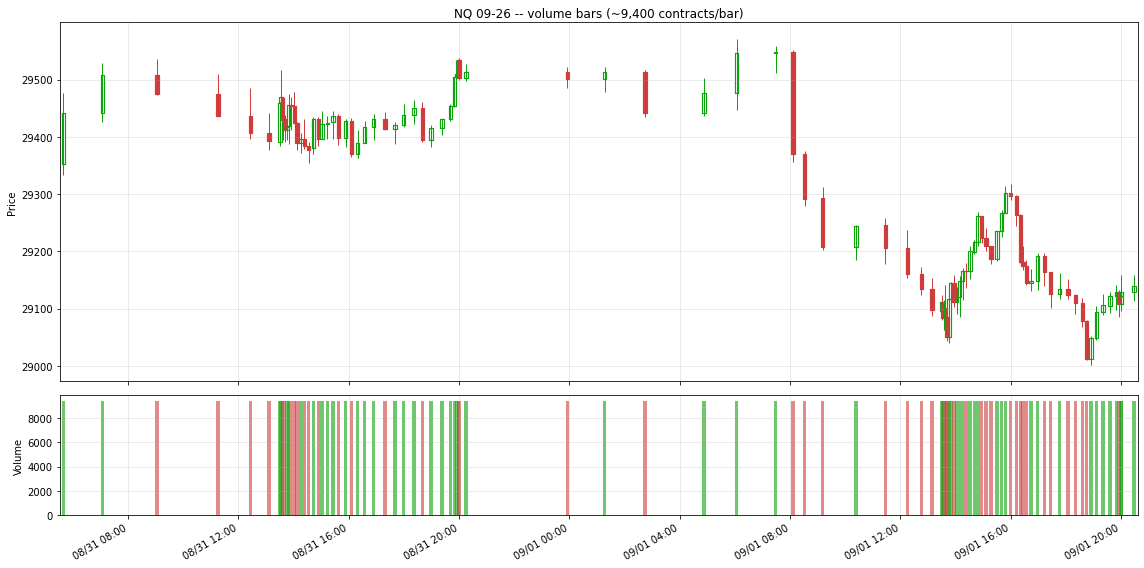

In [11]:
plot_candles(ohlcv_vol, f'NQ 09-26 -- volume bars (~{VOL_PER_BAR:,} contracts/bar)')

In [12]:
from scipy.stats import norm

def compute_vpin(volume_bars, window):
    """VPIN (Volume-Synchronized Probability of Informed Trading), bulk-
    volume-classification version (Easley/Lopez de Prado/O'Hara): each
    volume bucket's traded volume is split into buy/sell using the
    standard-normal CDF of its standardized price change -- no trade-by-
    trade tick rule needed, since bucket size is fixed at build time and the
    price move across the bucket stands in for order-flow direction. VPIN
    itself is the rolling mean of the buy/sell imbalance as a fraction of
    bucket volume: values near 0 = balanced flow, near 1 = one-sided
    ("toxic") flow.
    """
    dP = volume_bars['close'].diff()
    sigma = dP.std()
    buy_frac = norm.cdf(dP / sigma)
    v_buy = volume_bars['volume'] * buy_frac
    v_sell = volume_bars['volume'] - v_buy
    imbalance = (v_buy - v_sell).abs()
    return imbalance.rolling(window).sum() / volume_bars['volume'].rolling(window).sum()

# a shorter rolling window than the textbook 50 buckets, since this file is
# only ~1.7 trading days -- 50 would barely leave any VPIN history to look at
VPIN_WINDOW = 20
vpin = compute_vpin(ohlcv_vol, VPIN_WINDOW)
vpin.describe()

count    80.000000
mean      0.492713
std       0.060678
min       0.406660
25%       0.440215
50%       0.487007
75%       0.527368
max       0.645533
Name: volume, dtype: float64

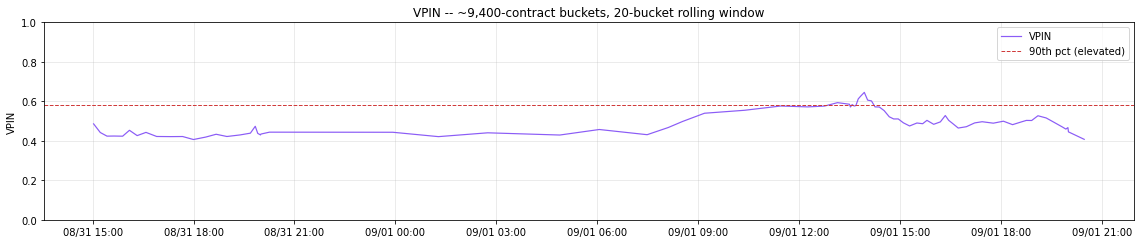

In [13]:
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.plot(ohlcv_vol.index, vpin, color='#8b5cf6', lw=1.2, label='VPIN')
ax.axhline(vpin.quantile(0.9), color='#d03b3b', ls='--', lw=1, label='90th pct (elevated)')
ax.set_title(f'VPIN -- ~{VOL_PER_BAR:,}-contract buckets, {VPIN_WINDOW}-bucket rolling window')
ax.set_ylabel('VPIN')
ax.set_ylim(0, 1)
ax.legend()
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.tight_layout()
plt.show()

In [14]:
# ---- making it testable: does elevated VPIN actually precede bigger moves? ----
# Event study: bucket every observation by its VPIN decile at the time, then
# compare the size of the price move over the NEXT few volume bars across
# deciles. If VPIN carries real information, higher deciles should show
# larger forward moves; a flat or noisy pattern means it doesn't, at least
# not on this instrument/window.
from scipy.stats import spearmanr

FORWARD_BARS = 5
fwd_abs_ret = ohlcv_vol['close'].pct_change(FORWARD_BARS).shift(-FORWARD_BARS).abs()

test_df = pd.DataFrame({'vpin': vpin, 'fwd_abs_ret': fwd_abs_ret}).dropna()
test_df['vpin_decile'] = pd.qcut(test_df['vpin'], 10, labels=False, duplicates='drop')

decile_summary = test_df.groupby('vpin_decile')['fwd_abs_ret'].agg(['mean', 'median', 'count'])
rho, pval = spearmanr(test_df['vpin'], test_df['fwd_abs_ret'])

print(f'usable observations: {len(test_df)}  (small-sample caveat: ~1.7 days of one instrument)')
print(f'Spearman rank correlation, VPIN vs forward {FORWARD_BARS}-bar |return|: '
      f'rho={rho:.3f}, p={pval:.4f}')
decile_summary

usable observations: 75  (small-sample caveat: ~1.7 days of one instrument)
Spearman rank correlation, VPIN vs forward 5-bar |return|: rho=0.030, p=0.7999


,mean,median,count
vpin_decile,,,
0,0.001670,0.000900,8
1,0.004230,0.002429,7
2,0.001985,0.001366,8
3,0.003412,0.001694,7
4,0.002231,0.002226,8
5,0.002815,0.002932,7
6,0.002439,0.002040,7
7,0.001744,0.000868,8
8,0.002283,0.002006,7


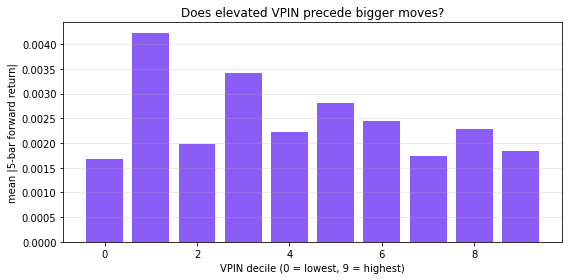

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(decile_summary.index, decile_summary['mean'], color='#8b5cf6')
ax.set_xlabel('VPIN decile (0 = lowest, 9 = highest)')
ax.set_ylabel(f'mean |{FORWARD_BARS}-bar forward return|')
ax.set_title('Does elevated VPIN precede bigger moves?')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [16]:
# ---- simple 21-SMA trend study: long above it, short below it ----
# Always in the market (no flat state) once the SMA has enough history to
# exist -- the simplest possible trend-following rule, on 1-minute bars.
SMA_PERIOD = 21
BAR_LABEL = '1-minute'
sma_df = ohlcv_1m.copy()
sma_df['sma21'] = sma_df['close'].rolling(SMA_PERIOD).mean()
sma_df['position'] = np.where(sma_df['close'] > sma_df['sma21'], 1, -1)
sma_df.loc[sma_df['sma21'].isna(), 'position'] = 0  # flat until the SMA exists

sma_df['bar_return'] = sma_df['close'].pct_change()
# trade executed on the bar AFTER the signal forms, so today's close isn't
# used to trade today's close (that would be lookahead)
sma_df['strategy_return'] = sma_df['position'].shift(1) * sma_df['bar_return']
sma_df['strategy_equity'] = (1 + sma_df['strategy_return'].fillna(0)).cumprod()
sma_df['buyhold_equity'] = (1 + sma_df['bar_return'].fillna(0)).cumprod()

def max_drawdown(equity):
    return (equity / equity.cummax() - 1).min()

n_flips = int((sma_df['position'].diff().fillna(0) != 0).sum())
strat_ret = sma_df['strategy_equity'].iloc[-1] - 1
bh_ret = sma_df['buyhold_equity'].iloc[-1] - 1

print(f'{SMA_PERIOD}-bar SMA on {BAR_LABEL} NQ bars ({len(sma_df)} bars)')
print(f'position flips (round-trip trades, roughly): {n_flips}')
print(f'strategy total return:  {strat_ret*100:+.2f}%   max drawdown: {max_drawdown(sma_df["strategy_equity"])*100:.2f}%')
print(f'buy & hold total return: {bh_ret*100:+.2f}%   max drawdown: {max_drawdown(sma_df["buyhold_equity"])*100:.2f}%')

# illustrative only -- ~1.7 days is nowhere near enough history to estimate
# a meaningful Sharpe ratio; shown for completeness, not as evidence of anything
bars_per_year = 252 * (23 * 60)  # NQ trades close to 23h/day, 1-minute bars
sharpe = sma_df['strategy_return'].mean() / sma_df['strategy_return'].std() * np.sqrt(bars_per_year)
print(f'(illustrative only, not meaningful at this sample size) annualized Sharpe: {sharpe:.2f}')

21-bar SMA on 1-minute NQ bars (2383 bars)
position flips (round-trip trades, roughly): 290
strategy total return:  -0.19%   max drawdown: -2.70%
buy & hold total return: -0.72%   max drawdown: -1.91%
(illustrative only, not meaningful at this sample size) annualized Sharpe: -1.82


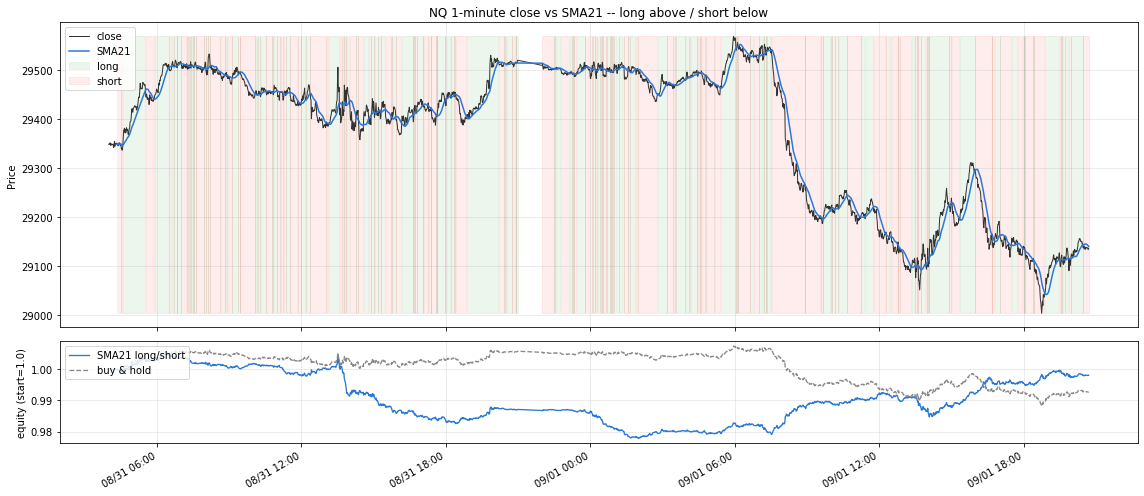

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
x = mdates.date2num(sma_df.index.to_pydatetime())

ax1.plot(x, sma_df['close'], color='#333333', lw=1, label='close')
ax1.plot(x, sma_df['sma21'], color='#2a78d6', lw=1.5, label=f'SMA{SMA_PERIOD}')
ax1.fill_between(x, sma_df['close'].min(), sma_df['close'].max(),
                  where=sma_df['position'] == 1, color='green', alpha=0.07, step='post', label='long')
ax1.fill_between(x, sma_df['close'].min(), sma_df['close'].max(),
                  where=sma_df['position'] == -1, color='red', alpha=0.07, step='post', label='short')
ax1.set_title(f'NQ {BAR_LABEL} close vs SMA{SMA_PERIOD} -- long above / short below')
ax1.set_ylabel('Price')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

ax2.plot(x, sma_df['strategy_equity'], color='#2a78d6', lw=1.3, label='SMA21 long/short')
ax2.plot(x, sma_df['buyhold_equity'], color='#888888', lw=1.3, ls='--', label='buy & hold')
ax2.set_ylabel('equity (start=1.0)')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.setp(ax2.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [18]:
# ---- reversed: short above the SMA, long below it ----
# Flipping the sign of a losing strategy's PnL every bar is NOT guaranteed
# to reverse the sign of the TOTAL return -- compounding is multiplicative,
# not additive, so a run of -1%, -1%, +3% and its mirror +1%, +1%, -3% do
# not end up as exact opposites, and drawdown depends on the path, not just
# the endpoint. So: actually compute it rather than assume.
rev_df = sma_df.copy()
rev_df['position'] = -sma_df['position']
rev_df['strategy_return'] = rev_df['position'].shift(1) * rev_df['bar_return']
rev_df['strategy_equity'] = (1 + rev_df['strategy_return'].fillna(0)).cumprod()

n_flips_rev = int((rev_df['position'].diff().fillna(0) != 0).sum())
strat_ret_rev = rev_df['strategy_equity'].iloc[-1] - 1

print(f'REVERSED: short above SMA{SMA_PERIOD} / long below it, on {BAR_LABEL} bars')
print(f'position flips: {n_flips_rev}  (same count as before -- flips happen at the same bars either way)')
print(f'original total return:  {strat_ret*100:+.2f}%   max drawdown: {max_drawdown(sma_df["strategy_equity"])*100:.2f}%')
print(f'reversed total return:  {strat_ret_rev*100:+.2f}%   max drawdown: {max_drawdown(rev_df["strategy_equity"])*100:.2f}%')
print(f'buy & hold total return: {bh_ret*100:+.2f}%   max drawdown: {max_drawdown(sma_df["buyhold_equity"])*100:.2f}%')

REVERSED: short above SMA21 / long below it, on 1-minute bars
position flips: 290  (same count as before -- flips happen at the same bars either way)
original total return:  -0.19%   max drawdown: -2.70%
reversed total return:  +0.18%   max drawdown: -2.21%
buy & hold total return: -0.72%   max drawdown: -1.91%


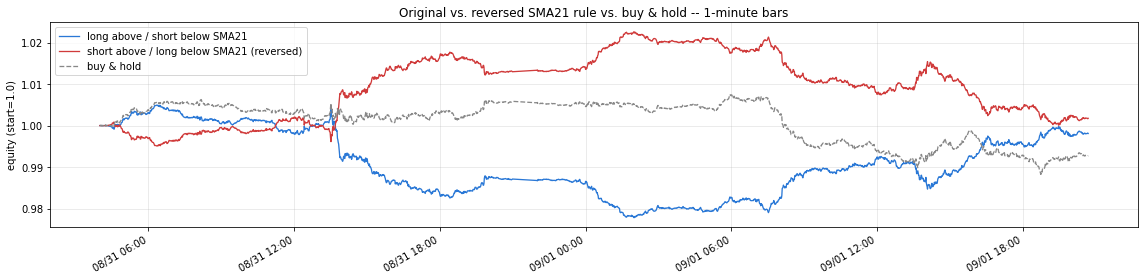

In [19]:
fig, ax = plt.subplots(figsize=(16, 4))
x = mdates.date2num(sma_df.index.to_pydatetime())
ax.plot(x, sma_df['strategy_equity'], color='#2a78d6', lw=1.3, label=f'long above / short below SMA{SMA_PERIOD}')
ax.plot(x, rev_df['strategy_equity'], color='#d03b3b', lw=1.3, label=f'short above / long below SMA{SMA_PERIOD} (reversed)')
ax.plot(x, sma_df['buyhold_equity'], color='#888888', lw=1.3, ls='--', label='buy & hold')
ax.set_title(f'Original vs. reversed SMA{SMA_PERIOD} rule vs. buy & hold -- {BAR_LABEL} bars')
ax.set_ylabel('equity (start=1.0)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [20]:
# ---- straddle + average-the-loser study ----
# Open long 1 unit AND short 1 unit at the same price. Whichever side hits
# +TARGET_POINTS first is closed for that profit. A second unit is then
# added to the OTHER (losing) side at that same extreme price, which
# averages its entry halfway back toward the original price. That 2-unit
# averaged position is held until EITHER price retraces RETRACE_PCT of the
# move (win) OR moves stop_distance points further beyond the extreme
# against it (loss, if stop_distance is given) -- whichever comes first. If
# neither happens before the data runs out, it's marked at the last price.
#
# Worst-case single-cycle loss with a stop is then a fixed, known number:
# -2*stop_distance (points), regardless of target size -- derived below,
# and confirmed by the sweep results. Without a stop (stop_distance=None)
# this reproduces the earlier run exactly.
TARGET_POINTS = 90
RETRACE_PCT = 0.45  # middle of the requested 40-50%

def simulate_straddle_average(bars, target_points, retrace_pct, stop_distance=None):
    trades = []
    i, n = 0, len(bars)
    while i < n:
        entry_price = bars['open'].iloc[i]
        entry_time = bars.index[i]

        winner_side, trigger_idx, ambiguous = None, None, False
        for j in range(i, n):
            hi, lo = bars['high'].iloc[j], bars['low'].iloc[j]
            hit_long = hi >= entry_price + target_points
            hit_short = lo <= entry_price - target_points
            if hit_long and hit_short:
                winner_side, trigger_idx, ambiguous = 'long', j, True  # can't tell order from OHLC alone
                break
            if hit_long:
                winner_side, trigger_idx = 'long', j; break
            if hit_short:
                winner_side, trigger_idx = 'short', j; break
        if winner_side is None:
            trades.append({'entry_time': entry_time, 'entry_price': entry_price,
                            'winner_side': None, 'cycle_pnl_points': 0.0,
                            'exit_reason': 'no_target_hit', 'exit_time': bars.index[-1]})
            break

        trigger_time = bars.index[trigger_idx]
        target_price = entry_price + target_points if winner_side == 'long' else entry_price - target_points
        loser_side = 'short' if winner_side == 'long' else 'long'
        loser_avg = (entry_price + target_price) / 2
        retrace_target = (target_price - retrace_pct * target_points if loser_side == 'short'
                           else target_price + retrace_pct * target_points)
        stop_price = None
        if stop_distance is not None:
            stop_price = (target_price + stop_distance if loser_side == 'short'
                          else target_price - stop_distance)

        exit_idx, exit_reason = None, None
        for k in range(trigger_idx + 1, n):
            hi, lo = bars['high'].iloc[k], bars['low'].iloc[k]
            hit_retrace = (lo <= retrace_target) if loser_side == 'short' else (hi >= retrace_target)
            hit_stop = (stop_price is not None) and ((hi >= stop_price) if loser_side == 'short' else (lo <= stop_price))
            if hit_retrace or hit_stop:
                # both hitting the same bar is possible only on an
                # implausibly wide 1-min bar (stop and retrace sit on
                # opposite sides of the extreme) -- default to retrace
                # (optimistic) in that rare tie, and flag it
                exit_idx = k
                exit_reason = 'retrace' if hit_retrace else 'stop'
                ambiguous = ambiguous or (hit_retrace and hit_stop)
                break
        reached = exit_idx is not None
        if reached:
            exit_price = retrace_target if exit_reason == 'retrace' else stop_price
        else:
            exit_price = bars['close'].iloc[-1]
        exit_time = bars.index[exit_idx] if reached else bars.index[-1]

        loser_pnl = (loser_avg - exit_price) * 2 if loser_side == 'short' else (exit_price - loser_avg) * 2
        cycle_pnl = target_points + loser_pnl

        trades.append({
            'entry_time': entry_time, 'entry_price': entry_price, 'winner_side': winner_side,
            'ambiguous_bar': ambiguous, 'loser_side': loser_side, 'loser_avg_price': loser_avg,
            'trigger_time': trigger_time, 'target_price': target_price,
            'retrace_target': retrace_target, 'stop_price': stop_price,
            'exit_reason': exit_reason if reached else 'data_end',
            'exit_time': exit_time, 'exit_price': exit_price, 'cycle_pnl_points': cycle_pnl,
        })
        if not reached:
            break
        i = exit_idx + 1

    return pd.DataFrame(trades)

trades_df = simulate_straddle_average(ohlcv_1m, TARGET_POINTS, RETRACE_PCT, stop_distance=45)
trades_df

,entry_time,entry_price,winner_side,ambiguous_bar,loser_side,loser_avg_price,trigger_time,target_price,retrace_target,stop_price,exit_reason,exit_time,exit_price,cycle_pnl_points
0,2026-08-31 04:00:00,29352.50,long,False,short,29397.50,2026-08-31 05:14:00,29442.50,29402.00,29487.50,stop,2026-08-31 06:06:00,29487.50,-90.0
1,2026-08-31 06:07:00,29470.25,short,False,long,29425.25,2026-08-31 12:55:00,29380.25,29420.75,29335.25,retrace,2026-08-31 13:17:00,29420.75,81.0
2,2026-08-31 13:18:00,29420.25,long,False,short,29465.25,2026-08-31 13:31:00,29510.25,29469.75,29555.25,retrace,2026-08-31 13:32:00,29469.75,81.0
3,2026-08-31 13:33:00,29467.75,short,False,long,29422.75,2026-08-31 14:06:00,29377.75,29418.25,29332.75,retrace,2026-08-31 14:17:00,29418.25,81.0
4,2026-08-31 14:18:00,29415.75,long,False,short,29460.75,2026-08-31 19:50:00,29505.75,29465.25,29550.75,retrace,2026-09-01 02:25:00,29465.25,81.0
5,2026-09-01 02:26:00,29465.25,long,False,short,29510.25,2026-09-01 05:55:00,29555.25,29514.75,29600.25,retrace,2026-09-01 06:29:00,29514.75,81.0
6,2026-09-01 06:30:00,29516.50,short,False,long,29471.50,2026-09-01 08:00:00,29426.50,29467.00,29381.50,stop,2026-09-01 08:06:00,29381.50,-90.0
7,2026-09-01 08:07:00,29360.00,short,False,long,29315.00,2026-09-01 08:37:00,29270.00,29310.50,29225.00,stop,2026-09-01 09:00:00,29225.00,-90.0
8,2026-09-01 09:01:00,29229.00,short,False,long,29184.00,2026-09-01 12:20:00,29139.00,29179.50,29094.00,stop,2026-09-01 13:06:00,29094.00,-90.0
9,2026-09-01 13:07:00,29092.00,long,False,short,29137.00,2026-09-01 14:30:00,29182.00,29141.50,29227.00,stop,2026-09-01 14:43:00,29227.00,-90.0


In [21]:
n_cycles = len(trades_df)
n_no_target = (trades_df['winner_side'].isna()).sum()
n_stopped = (trades_df['exit_reason'] == 'stop').sum()
n_data_end = (trades_df['exit_reason'] == 'data_end').sum()
total_pnl = trades_df['cycle_pnl_points'].sum()

print(f'cycles: {n_cycles}   (no target hit: {n_no_target}, stopped out: {n_stopped}, ran out of data: {n_data_end})')
print(f'total P&L: {total_pnl:.1f} points  (NQ = $20/pt -> ${total_pnl*20:,.0f} per contract-pair, no costs)')
print(f'worst single cycle: {trades_df["cycle_pnl_points"].min():.1f} pts   '
      f'best single cycle: {trades_df["cycle_pnl_points"].max():.1f} pts')
trades_df[['entry_time','winner_side','loser_side','exit_reason','exit_time','cycle_pnl_points']]

cycles: 15   (no target hit: 1, stopped out: 8, ran out of data: 0)
total P&L: -234.0 points  (NQ = $20/pt -> $-4,680 per contract-pair, no costs)
worst single cycle: -90.0 pts   best single cycle: 81.0 pts


,entry_time,winner_side,loser_side,exit_reason,exit_time,cycle_pnl_points
0,2026-08-31 04:00:00,long,short,stop,2026-08-31 06:06:00,-90.0
1,2026-08-31 06:07:00,short,long,retrace,2026-08-31 13:17:00,81.0
2,2026-08-31 13:18:00,long,short,retrace,2026-08-31 13:32:00,81.0
3,2026-08-31 13:33:00,short,long,retrace,2026-08-31 14:17:00,81.0
4,2026-08-31 14:18:00,long,short,retrace,2026-09-01 02:25:00,81.0
5,2026-09-01 02:26:00,long,short,retrace,2026-09-01 06:29:00,81.0
6,2026-09-01 06:30:00,short,long,stop,2026-09-01 08:06:00,-90.0
7,2026-09-01 08:07:00,short,long,stop,2026-09-01 09:00:00,-90.0
8,2026-09-01 09:01:00,short,long,stop,2026-09-01 13:06:00,-90.0
9,2026-09-01 13:07:00,long,short,stop,2026-09-01 14:43:00,-90.0


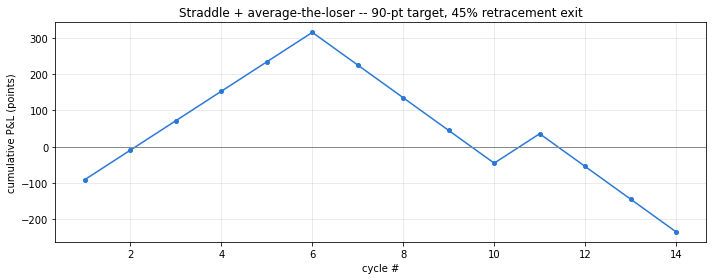

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
completed = trades_df.dropna(subset=['winner_side'])
ax.plot(range(1, len(completed) + 1), completed['cycle_pnl_points'].cumsum(),
        marker='o', ms=4, color='#2a78d6')
ax.axhline(0, color='#888', lw=1)
ax.set_xlabel('cycle #')
ax.set_ylabel('cumulative P&L (points)')
ax.set_title(f'Straddle + average-the-loser -- {TARGET_POINTS}-pt target, {RETRACE_PCT:.0%} retracement exit')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
# ---- sweep a few stop distances to see the tradeoff ----
# Tighter stop -> smaller worst-case loss, but also caps some cycles that
# would otherwise have gone on to retrace fine, turning a would-be +81 into
# a locked-in loss instead. That tradeoff, not a single "best" number, is
# the actual point of this sweep -- with only ~5-8 cycles of data, treat any
# single "winner" among these as anecdote, not a validated optimum.
STOP_CANDIDATES = [None, 30, 45, 60, 90, 135]

sweep_rows = []
sweep_trades = {}
for sd in STOP_CANDIDATES:
    df = simulate_straddle_average(ohlcv_1m, TARGET_POINTS, RETRACE_PCT, stop_distance=sd)
    sweep_trades[sd] = df
    sweep_rows.append({
        'stop_distance': sd if sd is not None else 'none',
        'cycles': len(df),
        'wins': (df['exit_reason'] == 'retrace').sum(),
        'stopped': (df['exit_reason'] == 'stop').sum(),
        'data_end': (df['exit_reason'] == 'data_end').sum(),
        'total_pnl_pts': df['cycle_pnl_points'].sum(),
        'worst_cycle_pts': df['cycle_pnl_points'].min(),
        'best_cycle_pts': df['cycle_pnl_points'].max(),
    })

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,stop_distance,cycles,wins,stopped,data_end,total_pnl_pts,worst_cycle_pts,best_cycle_pts
0,none,5,4,0,1,-218.5,-542.5,81.0
1,30,13,5,7,0,-15.0,-60.0,81.0
2,45,15,6,8,0,-234.0,-90.0,81.0
3,60,13,6,6,0,-234.0,-120.0,81.0
4,90,12,6,5,0,-414.0,-180.0,81.0
5,135,11,8,2,1,74.0,-270.0,81.0


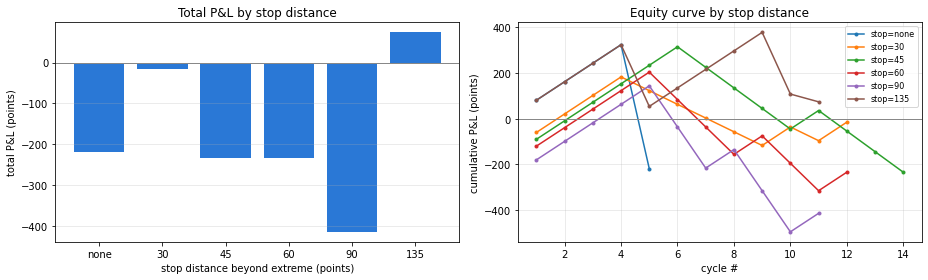

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

labels = [str(s) for s in sweep_df['stop_distance']]
ax1.bar(labels, sweep_df['total_pnl_pts'], color='#2a78d6')
ax1.axhline(0, color='#888', lw=1)
ax1.set_xlabel('stop distance beyond extreme (points)')
ax1.set_ylabel('total P&L (points)')
ax1.set_title('Total P&L by stop distance')
ax1.grid(True, alpha=0.3, axis='y')

for sd in STOP_CANDIDATES:
    df = sweep_trades[sd]
    completed = df.dropna(subset=['winner_side'])
    ax2.plot(range(1, len(completed) + 1), completed['cycle_pnl_points'].cumsum(),
             marker='o', ms=3, label=f'stop={sd if sd is not None else "none"}')
ax2.axhline(0, color='#888', lw=1)
ax2.set_xlabel('cycle #')
ax2.set_ylabel('cumulative P&L (points)')
ax2.set_title('Equity curve by stop distance')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
# what "stop_distance=135" actually means in price terms, using the real trades
sweep_trades[135][['entry_time','entry_price','winner_side','loser_avg_price',
                    'retrace_target','stop_price','exit_reason','exit_price','cycle_pnl_points']]

,entry_time,entry_price,winner_side,loser_avg_price,retrace_target,stop_price,exit_reason,exit_price,cycle_pnl_points
0,2026-08-31 04:00:00,29352.50,long,29397.50,29402.00,29577.50,retrace,29402.00,81.0
1,2026-08-31 12:10:00,29447.00,short,29402.00,29397.50,29222.00,retrace,29397.50,81.0
2,2026-08-31 14:36:00,29402.00,long,29447.00,29451.50,29627.00,retrace,29451.50,81.0
3,2026-09-01 02:36:00,29452.00,long,29497.00,29501.50,29677.00,retrace,29501.50,81.0
4,2026-09-01 07:37:00,29498.00,short,29453.00,29448.50,29273.00,stop,29273.00,-270.0
5,2026-09-01 08:38:00,29268.50,short,29223.50,29219.00,29043.50,retrace,29219.00,81.0
6,2026-09-01 11:31:00,29219.75,short,29174.75,29170.25,28994.75,retrace,29170.25,81.0
7,2026-09-01 14:16:00,29158.25,long,29203.25,29207.75,29383.25,retrace,29207.75,81.0
8,2026-09-01 14:58:00,29212.00,long,29257.00,29261.50,29437.00,retrace,29261.50,81.0
9,2026-09-01 16:07:00,29261.25,short,29216.25,29211.75,29036.25,stop,29036.25,-270.0


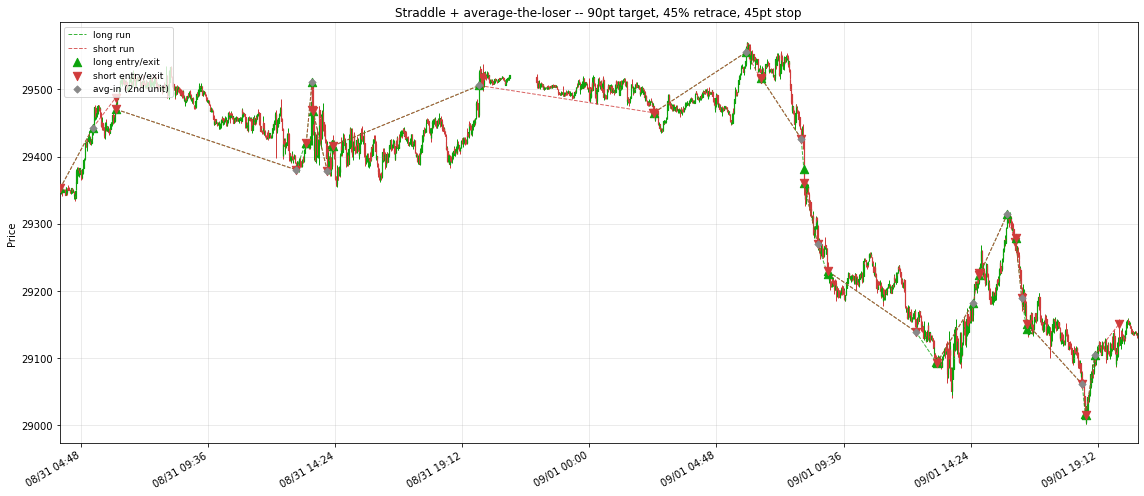

In [26]:
# ---- chart the actual long/short legs of each cycle on the candles ----
# Green upward triangle = a point belonging to the LONG leg (its entry or
# wherever it finally closed); red downward triangle = the SHORT leg,
# same idea. A dashed line in that same color connects each leg's own
# entry to its own exit -- "the run of the trade" -- so a long run that
# drifts down and a short run that drifts up are both visible at a glance.
# A small gray diamond marks the averaging-in point on the losing leg.
def plot_trades(ohlcv, trades_df, title, up='#0ca30c', down='#d03b3b'):
    x = mdates.date2num(ohlcv.index.to_pydatetime())
    o, h, l, c = (ohlcv[col].values for col in ['open', 'high', 'low', 'close'])
    is_up = c >= o
    colors = np.where(is_up, up, down)
    width = (np.median(np.diff(x)) * 0.62) if len(x) > 1 else 1 / 1440

    fig, ax = plt.subplots(figsize=(16, 7))
    segs = [[(xi, li), (xi, hi)] for xi, li, hi in zip(x, l, h)]
    ax.add_collection(LineCollection(segs, colors=colors, linewidths=1))
    price_span = h.max() - l.min()
    min_body = max(price_span * 0.0008, 1e-6)
    patches = [Rectangle((xi - width / 2, min(oi, ci)), width, max(abs(ci - oi), min_body))
               for xi, oi, ci in zip(x, o, c)]
    face = ['none' if u else col for u, col in zip(is_up, colors)]
    pc = PatchCollection(patches, facecolor=face, edgecolor=list(colors), linewidths=1.2)
    ax.add_collection(pc)
    ax.set_xlim(x.min() - width, x.max() + width)
    ax.set_ylim(l.min() - price_span * 0.05, h.max() + price_span * 0.05)

    LONG_COLOR, SHORT_COLOR = '#0ca30c', '#d03b3b'
    long_label_used = short_label_used = avg_label_used = False

    for _, row in trades_df.dropna(subset=['winner_side']).iterrows():
        entry_x = mdates.date2num(row['entry_time'])
        trigger_x = mdates.date2num(row['trigger_time'])
        exit_x = mdates.date2num(row['exit_time'])
        winner, loser = row['winner_side'], row['loser_side']

        # each leg's own (time, price) path: entry -> [avg-in, if it's the
        # loser] -> its own final close
        long_path = ([entry_x, trigger_x] if winner == 'long' else [entry_x, trigger_x, exit_x])
        long_prices = ([row['entry_price'], row['target_price']] if winner == 'long'
                        else [row['entry_price'], row['target_price'], row['exit_price']])
        short_path = ([entry_x, trigger_x] if winner == 'short' else [entry_x, trigger_x, exit_x])
        short_prices = ([row['entry_price'], row['target_price']] if winner == 'short'
                         else [row['entry_price'], row['target_price'], row['exit_price']])

        ax.plot(long_path, long_prices, color=LONG_COLOR, ls='--', lw=1, alpha=0.8,
                 label='long run' if not long_label_used else None)
        ax.plot(short_path, short_prices, color=SHORT_COLOR, ls='--', lw=1, alpha=0.8,
                 label='short run' if not short_label_used else None)
        long_label_used = short_label_used = True

        # entries (both legs open at the same point)
        ax.scatter(entry_x, row['entry_price'], marker='^', s=70, color=LONG_COLOR, zorder=5,
                    label='long entry/exit' if not avg_label_used else None)
        ax.scatter(entry_x, row['entry_price'], marker='v', s=70, color=SHORT_COLOR, zorder=5,
                    label='short entry/exit' if not avg_label_used else None)
        # each leg's own final close
        ax.scatter(trigger_x if winner == 'long' else exit_x,
                    row['target_price'] if winner == 'long' else row['exit_price'],
                    marker='^', s=70, color=LONG_COLOR, zorder=5)
        ax.scatter(trigger_x if winner == 'short' else exit_x,
                    row['target_price'] if winner == 'short' else row['exit_price'],
                    marker='v', s=70, color=SHORT_COLOR, zorder=5)
        # averaging-in point on the loser leg
        ax.scatter(trigger_x, row['target_price'], marker='D', s=25, color='#888888', zorder=6,
                    label='avg-in (2nd unit)' if not avg_label_used else None)
        avg_label_used = True

    ax.set_title(title)
    ax.set_ylabel('Price')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d %H:%M'))
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    plt.tight_layout()
    plt.show()

plot_trades(ohlcv_1m, trades_df, f'Straddle + average-the-loser -- {TARGET_POINTS}pt target, '
                                   f'{RETRACE_PCT:.0%} retrace, 45pt stop')